## Exploratory Data Analysis

In [1]:
import numpy as np
import helpers
import csv
import implementations as imp
import matplotlib.pyplot as plt
import diagstat as ds

### 1. Loading Data

In [2]:
x_train, x_test, y_train, train_ids, test_ids = helpers.load_csv_data("data/dataset")
full_headers = helpers.read_header("data/dataset/x_train.csv")
print(x_train[0:10, :])
print(full_headers)

[[5.3000000e+01 1.1000000e+01 1.1162015e+07 ...           nan
            nan 2.0000000e+00]
 [3.3000000e+01 1.2000000e+01 1.2152015e+07 ...           nan
            nan           nan]
 [2.0000000e+01 1.0000000e+01 1.0202015e+07 ... 1.0000000e+00
  2.0000000e+00 2.0000000e+00]
 ...
 [4.4000000e+01 3.0000000e+00 3.0720150e+06 ... 1.0000000e+00
  2.0000000e+00 2.0000000e+00]
 [2.1000000e+01 7.0000000e+00 7.3120150e+06 ...           nan
            nan 2.0000000e+00]
 [4.0000000e+00 6.0000000e+00 6.2320150e+06 ...           nan
            nan           nan]]
['_STATE' 'FMONTH' 'IDATE' 'IMONTH' 'IDAY' 'IYEAR' 'DISPCODE' 'SEQNO'
 '_PSU' 'CTELENUM' 'PVTRESD1' 'COLGHOUS' 'STATERES' 'CELLFON3' 'LADULT'
 'NUMADULT' 'NUMMEN' 'NUMWOMEN' 'CTELNUM1' 'CELLFON2' 'CADULT' 'PVTRESD2'
 'CCLGHOUS' 'CSTATE' 'LANDLINE' 'HHADULT' 'GENHLTH' 'PHYSHLTH' 'MENTHLTH'
 'POORHLTH' 'HLTHPLN1' 'PERSDOC2' 'MEDCOST' 'CHECKUP1' 'BPHIGH4' 'BPMEDS'
 'BLOODCHO' 'CHOLCHK' 'TOLDHI2' 'CVDSTRK3' 'ASTHMA3' 'ASTHNOW' 'CHCSCNCR

In [3]:
print("Size of Data:", np.shape(x_train))
print(x_train[0:10,0])

Size of Data: (328135, 321)
[53. 33. 20. 42. 24. 54. 39. 44. 21.  4.]


The Id column and variables names aren't loaded by the helper function `load_csv_data` so we need to manually keep track of the column headers.

### 2. Select only Calculated Variables and Clean

In [4]:
x_train_calculated = x_train[:,-91:] 
calculated_headers = full_headers[-91:]
print(len(calculated_headers))

91


The following steps of initial cleaning are taken:

1. Remove variables are just used to measure the quality of the response. They are not needed for this stage but can be added back later. This includes the following:

  - `_MISVEGN`, `_MISFRTN`, `_FRTRESP`, `_VEGRESP`, `_FRUITEX`, `_VEGETEX`, `_FRT16`, `_VEG23`, `PAMISS1_`

2. If multiple variables actually measure the same thing, then only one is needed to be kept. This includes the following:

  - `HTIN4` and `HTM4`: keep only `HTM4`
  - Most of the variables containing age and race information: keep only `_AGE80` and `_RACE`

3. Remove variables that are an exact linear combination or a function of some other variables. This includes the following:

  - `FC60_` and `MAXVO2_`: one is (almost) an exact multiple of the other, we keep `FC60_`.
  - `PA1MIN_` and `PA1VIGM_`: exact sums of the per-activity minutes (`PAMIN11_ + PAMIN21_` and `PAVIG11_ + PAVIG21_`)
  - `FTJUDA1_`, `FRUTDA1_`, `BEANDAY_`, `GRENDAY_`, `ORNGDAY_`, `VEGEDA1_`: exact components of `_FRUTSUM` and `_VEGESUM` — we keep the two sums
  - `_RFSMOK3`: `== 2` exactly when `_SMOKER3 in {1, 2}` (current smoker)
  - `_RFBMI5` and `_BMI5CAT`: threshold (`_BMI5 >= 25`) and buckets (18.5 / 25 / 30) of `_BMI5`
  - `_FRTLT1` and `_VEGLT1`: `== 1` exactly when `_FRUTSUM >= 1` / `_VEGESUM >= 1`
  - `DRNKANY5`: `== 1` exactly when `_DRNKWEK > 0`
  - `_PASTRNG`: `== 1` exactly when `STRFREQ_ >= 2` (strength training twice a week)
  - `_PAREC1`: exact 2x2 cross of `_PAINDX1` and `_PASTRNG`; `_PAINDX1`, `_PA30021` and `_PASTAE1` are exact collapses of `_PA150R2`, `_PA300R2` and `_PAREC1`
  - `_DRDXAR1`: `== 1` exactly when `_LMTACT1 in {1, 2}` (diagnosed with arthritis)
  - `_LTASTH1` and `_CASTHM1`: `_ASTHMS1` is their exact three-way merge (never/former/current asthma)

In [5]:
drop_list = [
       # response quality
       "_MISVEGN", "_MISFRTN", "_FRTRESP", "_VEGRESP",
       "_FRUITEX", "_VEGETEX", "_FRT16", "_VEG23", "PAMISS1_",
       # age/race duplicates (keep _AGE80, _RACE)
       "_AGEG5YR", "_AGE_G", "_AGE65YR",
       "_PRACE1", "_MRACE1", "_HISPANC", "_RACEG21", "_RACEGR3", "_RACE_G1",
       # exact duplicates/ rescales
       "HTIN4",                                          
       "MAXVO2_",                                        
       # overlapping info
       "PA1MIN_", "PA1VIGM_",
       "FTJUDA1_", "FRUTDA1_",                            
       "BEANDAY_", "GRENDAY_", "ORNGDAY_", "VEGEDA1_",    
       "_RFSMOK3", "_RFBMI5", "_BMI5CAT",
       "_FRTLT1", "_VEGLT1", "DRNKANY5", "_PASTRNG",
       "_PAREC1", "_PAINDX1", "_PA30021", "_PASTAE1",
       "_DRDXAR1", "_LTASTH1", "_CASTHM1",
]

col_idx = np.where(np.isin(calculated_headers, drop_list))[0]
x_train_cal_cleaned = np.delete(x_train_calculated, col_idx, axis=1)
cal_headers_cleaned = np.delete(calculated_headers, col_idx)   
print("Remaining columns:", len(cal_headers_cleaned))
print(cal_headers_cleaned)

Remaining columns: 49
['_RFHLTH' '_HCVU651' '_RFHYPE5' '_CHOLCHK' '_RFCHOL' '_ASTHMS1' '_RACE'
 '_AGE80' 'HTM4' 'WTKG3' '_BMI5' '_CHLDCNT' '_EDUCAG' '_INCOMG' '_SMOKER3'
 'DROCDY3_' '_RFBING5' '_DRNKWEK' '_RFDRHV5' '_FRUTSUM' '_VEGESUM'
 '_TOTINDA' 'METVL11_' 'METVL21_' 'FC60_' 'ACTIN11_' 'ACTIN21_' 'PADUR1_'
 'PADUR2_' 'PAFREQ1_' 'PAFREQ2_' '_MINAC11' '_MINAC21' 'STRFREQ_'
 'PAMIN11_' 'PAMIN21_' 'PAVIG11_' 'PAVIG21_' '_PACAT1' '_PA150R2'
 '_PA300R2' '_LMTACT1' '_LMTWRK1' '_LMTSCL1' '_RFSEAT2' '_RFSEAT3'
 '_FLSHOT6' '_PNEUMO2' '_AIDTST3']


Before we start handling the NANs, the data should be splitted into numerical data and categorical datd and only pure categorical data needs one_hot. Some categorical data are still treated as numerical data (see `headers_numeric_cat`) because in their cases, larger cateogrical numbers do correspond to larger underlying values they are measuring.

The placement of these variables are done manually by checking the codebook. 

In [6]:
headers_numeric_cat = ["_AGEG5YR", "_AGE_G", "_BMI5CAT", "_CHLDCNT", "_EDUCAG", "_INCOMG", "_MISVEGN",
                        "ACTIN11_", "ACTIN21_", "_PACAT1", "_PA150R2", "_PA300R2", "_SMOKER3"]
headers_cat = ["_CHOLCHK", "_ASTHMS1", "_PRACE1", "_MRACE1", "_RACE", "_RACEGR3", "_RACE_G1",
                        "_PAREC1", "_LMTACT1", "_LMTWRK1", "_LMTSCL1", ]
headers_numeric = ["_AGE80", "HTIN4", "HTM4", "WTKG3", "_BMI5", "DROCDY3_", "_DRNKWEK", "FTJUDA1_",
                        "FRUTDA1_", "BEANDAY_", "GRENDAY_", "ORNGDAY_", "VEGEDA1_", "_FRUTSUM", "_VEGESUM", 
                        "METVL11_", "METVL21_", "MAXVO2_", "FC60_", "PADUR1_", "PADUR2_", "PAFREQ1_", "PAFREQ2_",
                        "_MINAC11", "_MINAC21", "STRFREQ_", "PAMIN11_", "PAMIN21_", "PA1MIN_", "PAVIG11_", "PAVIG21_",
                        "PA1VIGM_"]

# Every other variable not in this list is a binary variable, i.e. a variable who, apart from missing/unknown flag, 
# only has binary values. 
# We then filter out those that are in the drop list

headers_num_cat_cleaned = [header for header in headers_numeric_cat if header not in drop_list]
headers_cat_cleaned = [header for header in headers_cat if header not in drop_list]
headers_num_cleaned = [header for header in headers_numeric if header not in drop_list]

print("Numerical-categorical (ordinal) headers:", len(headers_num_cat_cleaned))
print(headers_num_cat_cleaned)
print("Categorical headers:", len(headers_cat_cleaned))
print(headers_cat_cleaned)
print("Numerical headers:", len(headers_num_cleaned))
print(headers_num_cleaned)

Numerical-categorical (ordinal) headers: 9
['_CHLDCNT', '_EDUCAG', '_INCOMG', 'ACTIN11_', 'ACTIN21_', '_PACAT1', '_PA150R2', '_PA300R2', '_SMOKER3']
Categorical headers: 6
['_CHOLCHK', '_ASTHMS1', '_RACE', '_LMTACT1', '_LMTWRK1', '_LMTSCL1']
Numerical headers: 22
['_AGE80', 'HTM4', 'WTKG3', '_BMI5', 'DROCDY3_', '_DRNKWEK', '_FRUTSUM', '_VEGESUM', 'METVL11_', 'METVL21_', 'FC60_', 'PADUR1_', 'PADUR2_', 'PAFREQ1_', 'PAFREQ2_', '_MINAC11', '_MINAC21', 'STRFREQ_', 'PAMIN11_', 'PAMIN21_', 'PAVIG11_', 'PAVIG21_']


For NANs (possibly encoded numerically, e.g. as 7 or 9), due to the annoying fact that each column encodes their NANs somewhat differently, we will have to handle all these 49 columns individually. Let's first look at headers in `headers_num_cat_cleaned`.

Luckily, except for `ACTIN11_` and `ACTIN21_` whose mising values are indicated as BLANK (NAN), for all the others the missing values are indicated as $9$. As an initial attempt I will replace every nan with mode except for `ACTIN11_` and `ACTIN21_`. For these two, if `_PACAT1` is $4$ (inactive), we can reasonably assume they are 0 (Not Moderate or Vigorous or No Activity), otherwise we should use mode.

In [7]:
pacat1_data = x_train_cal_cleaned[:, int(np.where(cal_headers_cleaned == "_PACAT1")[0][0])]
for header in headers_num_cat_cleaned:
    idx = int(np.where(cal_headers_cleaned == header)[0][0])
    col = x_train_cal_cleaned[:, idx]
    if header == 'ACTIN11_' or header == 'ACTIN21_':
        m = np.isnan(col)
        values, counts = np.unique(col[~m], return_counts=True)
        mode = values[np.argmax(counts)]              
        col[m & (pacat1_data == 4)] = 0          
        col[m & (pacat1_data != 4)] = mode
        print(f"Column {header}: {np.sum(m & (pacat1_data == 4))} NaNs filled by 0; ",
            f"{np.sum(m & (pacat1_data != 4))} filled with mode = {mode}")
    else:
        col[col == 9.0] = np.nan
        observed = col[~np.isnan(col)]
        values, counts = np.unique(observed, return_counts=True)
        mode = values[np.argmax(counts)] 
        col[np.isnan(col)] = mode
        print(f"Column {header}: NANs filled with mode = {mode}")
    x_train_cal_cleaned[:, idx] = col


Column _CHLDCNT: NANs filled with mode = 1.0
Column _EDUCAG: NANs filled with mode = 4.0
Column _INCOMG: NANs filled with mode = 5.0
Column ACTIN11_: 79581 NaNs filled by 0;  31491 filled with mode = 1.0
Column ACTIN21_: 79581 NaNs filled by 0;  35117 filled with mode = 0.0
Column _PACAT1: NANs filled with mode = 1.0
Column _PA150R2: NANs filled with mode = 1.0
Column _PA300R2: NANs filled with mode = 2.0
Column _SMOKER3: NANs filled with mode = 4.0


Next, we will be dealing with `headers_cat`. Since unlike categorical numerical data, they don't carry ordinal relations, it's safe to let NANs $(9)$ be their own category. And for `_LMTACT1`, `_LMTWRK1`, `_LMTSCL1`, they have both $9$ and actual NANs, so will be normalised to $9$.

In [8]:
for header in headers_cat_cleaned:
    idx = int(np.where(cal_headers_cleaned == header)[0][0])
    col = x_train_cal_cleaned[:, idx]
    print(f"Column {header}: {np.sum(np.isnan(col))} NANs replaced by 9")
    col[np.isnan(col)] = 9.0
    x_train_cal_cleaned[:, idx] = col


Column _CHOLCHK: 0 NANs replaced by 9
Column _ASTHMS1: 0 NANs replaced by 9
Column _RACE: 0 NANs replaced by 9
Column _LMTACT1: 1883 NANs replaced by 9
Column _LMTWRK1: 1883 NANs replaced by 9
Column _LMTSCL1: 1883 NANs replaced by 9


The remaining groups are numerical data (`headers_numeric`) and binary data. For them we may as well just replace NANs with mean, median or mode. TBD...

In [9]:
encoded_nan = {
       "DROCDY3_": 900.0, "_DRNKWEK": 99900.0, "FC60_": 999.0,
       "STRFREQ_": 99.0, "PAFREQ1_": 99.0, "PAFREQ2_": 99.0,
   }
for header in headers_num_cleaned:
    idx = int(np.where(cal_headers_cleaned == header)[0][0])
    col = x_train_cal_cleaned[:, idx]
    if header in encoded_nan.keys():
        col[col == encoded_nan[header]] = np.nan
    med = np.nanmedian(col)
    nan_count = np.sum(np.isnan(col))
    col[np.isnan(col)] = med
    print(f"Column {header}: {nan_count} NANs replaced by median =", med)
    x_train_cal_cleaned[:, idx] = col

Column _AGE80: 0 NANs replaced by median = 58.0
Column HTM4: 11368 NANs replaced by median = 1.68
Column WTKG3: 23006 NANs replaced by median = 77.56
Column _BMI5: 27073 NANs replaced by median = 26.93
Column DROCDY3_: 15974 NANs replaced by median = 3.0
Column _DRNKWEK: 18967 NANs replaced by median = 23.0
Column _FRUTSUM: 32115 NANs replaced by median = 1.0
Column _VEGESUM: 37605 NANs replaced by median = 1.7
Column METVL11_: 108727 NANs replaced by median = 3.5
Column METVL21_: 112425 NANs replaced by median = 3.5
Column FC60_: 3943 NANs replaced by median = 4.63
Column PADUR1_: 113793 NANs replaced by median = 45.0
Column PADUR2_: 184643 NANs replaced by median = 45.0
Column PAFREQ1_: 111271 NANs replaced by median = 3.5
Column PAFREQ2_: 182929 NANs replaced by median = 2.333
Column _MINAC11: 115152 NANs replaced by median = 140.0
Column _MINAC21: 116821 NANs replaced by median = 33.0
Column STRFREQ_: 32510 NANs replaced by median = 0.0
Column PAMIN11_: 117355 NANs replaced by medi

In [10]:
for header in cal_headers_cleaned[np.isin(cal_headers_cleaned, np.concatenate((headers_num_cat_cleaned, headers_cat_cleaned,headers_num_cleaned)), invert=True)]:
    idx = int(np.where(cal_headers_cleaned == header)[0][0])
    col = x_train_cal_cleaned[:, idx]
    col[col == 9.0] = np.nan
    observed = col[~np.isnan(col)]
    values, counts = np.unique(observed, return_counts=True)
    mode = values[np.argmax(counts)] 
    nan_count = np.sum(np.isnan(col))
    col[np.isnan(col)] = mode
    print(f"Column {header}: {nan_count} NANs replaced by mode =", mode)
    x_train_cal_cleaned[:, idx] = col

Column _RFHLTH: 888 NANs replaced by mode = 1.0
Column _HCVU651: 117708 NANs replaced by mode = 1.0
Column _RFHYPE5: 918 NANs replaced by mode = 1.0
Column _RFCHOL: 46324 NANs replaced by mode = 1.0
Column _RFBING5: 18858 NANs replaced by mode = 1.0
Column _RFDRHV5: 18967 NANs replaced by mode = 1.0
Column _TOTINDA: 28067 NANs replaced by mode = 1.0
Column _RFSEAT2: 31643 NANs replaced by mode = 1.0
Column _RFSEAT3: 31643 NANs replaced by mode = 1.0
Column _FLSHOT6: 225364 NANs replaced by mode = 1.0
Column _PNEUMO2: 228590 NANs replaced by mode = 1.0
Column _AIDTST3: 42783 NANs replaced by mode = 2.0


In [11]:
# Normalise binary data to 0, 1
for header in cal_headers_cleaned[np.isin(cal_headers_cleaned, np.concatenate((headers_num_cat_cleaned, headers_cat_cleaned,headers_num_cleaned)), invert=True)]:
    idx = int(np.where(cal_headers_cleaned == header)[0][0])
    col = x_train_cal_cleaned[:, idx]
    col[col == 1.0] = 0.0
    col[col == 2.0] = 1.0
    x_train_cal_cleaned[:, idx] = col

### 3. K-fold Split and Test Model

In [12]:
print(helpers.k_fold_split(len(y_train), K=30))

[(array([306110, 173513,  82820, ...,  48632, 120609, 164447],
      shape=(317197,)), array([254903,  57722, 220912, ...,   1252,  80407,  11031],
      shape=(10938,))), (array([254903,  57722, 220912, ...,  48632, 120609, 164447],
      shape=(317197,)), array([306110, 173513,  82820, ..., 145372, 155405, 292125],
      shape=(10938,))), (array([254903,  57722, 220912, ...,  48632, 120609, 164447],
      shape=(317197,)), array([243888, 190366,  38539, ..., 274513, 241201, 188693],
      shape=(10938,))), (array([254903,  57722, 220912, ...,  48632, 120609, 164447],
      shape=(317197,)), array([288064, 162774, 126261, ..., 266652, 327289, 160072],
      shape=(10938,))), (array([254903,  57722, 220912, ...,  48632, 120609, 164447],
      shape=(317197,)), array([259971, 127133,  90295, ..., 156342, 325588,  92173],
      shape=(10938,))), (array([254903,  57722, 220912, ...,  48632, 120609, 164447],
      shape=(317197,)), array([257370,  68993, 207935, ...,  42881, 311006, 277152

In [13]:
from tqdm import tqdm 
# All it does is showing a progress bar, still we should delete it before final submission

x_tr_one_hot, header_one_hot = helpers.one_hot(x_train_cal_cleaned, headers_cat_cleaned, cal_headers_cleaned)
print("Data dimensions after one-hot:", np.shape(x_tr_one_hot))

# Normalise a bit
y_train[y_train == -1] = 0

K = 5
folds_list = helpers.k_fold_split(len(y_train), K)
max_iters = 500
gamma_list = [0.1] # Set like this for now, add more candidates later
reg_list = np.logspace(-5, -1, 4)
results = []
for gamma in gamma_list:
    for lam in reg_list:
        tr_losses, val_losses, zero_one, aucs = [], [], [], []
        val_scores = np.zeros(len(y_train))
        fold_state = []
        for fold in tqdm(folds_list):
            x_tr_fold, y_tr_fold = x_tr_one_hot[fold[0]], y_train[fold[0]]
            # Centering and normalising
            std = x_tr_fold.std(axis = 0)
            mu = x_tr_fold.mean(axis = 0)
            std[std == 0] = 1
            x_tr_fold = np.c_[np.ones(len(x_tr_fold[:,0])), (x_tr_fold - mu) / std]
            x_val_fold, y_val_fold = x_tr_one_hot[fold[1]], y_train[fold[1]]
            x_val_fold = np.c_[np.ones(len(x_val_fold)), (x_val_fold - mu) / std]
            w_init = np.zeros(len(x_tr_fold[0,:]))
            w_fold, loss_fold = imp.reg_logistic_regression(y_tr_fold, x_tr_fold, lam, w_init, max_iters, gamma)
            
            tr_losses.append(loss_fold)
            val_losses.append(imp.logistic_loss(y_val_fold, x_val_fold, w_fold))
            val_score = 0.5 * (1 + np.tanh(0.5 * x_val_fold.dot(w_fold)))
            zero_one.append(np.mean((val_score > 0.5) != y_val_fold))
            fold_state.append({"w": w_fold, "mu": mu, "sd": std, "val_idx": fold[1]})
            
            false_pos_rate, true_pos_rate, auc_fold = ds.ROC_AUC(y_val_fold, val_score)
            aucs.append(auc_fold)
            val_scores[fold[1]] = val_score
            
        results.append({
            "gamma": gamma, "lam": lam,
            "train_loss": np.mean(tr_losses),
            "val_loss": np.mean(val_losses), "val_loss_std": np.std(val_losses),
            "01_loss": np.mean(zero_one),
            "gap": np.mean(val_losses) - np.mean(tr_losses),
            "val_scores": val_scores,
            "mean_auc": np.mean(aucs),
            "fold_state": fold_state
        })
        print("---Result---")
        print(f"learning rate = {gamma}, regulariser = {lam:.1e}:")
        print(f"validation logistic loss = {results[-1]['val_loss']:.4f}±{results[-1]['val_loss_std']:.4f}, 0-1 loss (proportion of mistake) = {results[-1]['01_loss']:.4f}, train & validation loss gap = {results[-1]['gap']:.4f}")
        print(f"mean AUC across fold = {results[-1]['mean_auc']:.4f}")
        print("------------")

Data dimensions after one-hot: (328135, 73)


100%|██████████| 5/5 [01:16<00:00, 15.22s/it]


---Result---
learning rate = 0.1, regulariser = 1.0e-05:
validation logistic loss = 0.2373±0.0013, 0-1 loss (proportion of mistake) = 0.0881, train & validation loss gap = 0.0002
mean AUC across fold = 0.8345
------------


100%|██████████| 5/5 [01:03<00:00, 12.66s/it]


---Result---
learning rate = 0.1, regulariser = 2.2e-04:
validation logistic loss = 0.2375±0.0013, 0-1 loss (proportion of mistake) = 0.0881, train & validation loss gap = 0.0002
mean AUC across fold = 0.8345
------------


100%|██████████| 5/5 [01:12<00:00, 14.50s/it]


---Result---
learning rate = 0.1, regulariser = 4.6e-03:
validation logistic loss = 0.2445±0.0012, 0-1 loss (proportion of mistake) = 0.0879, train & validation loss gap = 0.0001
mean AUC across fold = 0.8341
------------


100%|██████████| 5/5 [01:06<00:00, 13.37s/it]

---Result---
learning rate = 0.1, regulariser = 1.0e-01:
validation logistic loss = 0.3861±0.0008, 0-1 loss (proportion of mistake) = 0.0883, train & validation loss gap = 0.0000
mean AUC across fold = 0.8262
------------


From the raw $0-1$ loss our model is not good, in fact worse than the trivial model that gives every sample a prediction of $0$.

We will also check the ROC and AUC. But clearly we need better parameters.

Text(0.5, 1.0, 'Pooled ROC')

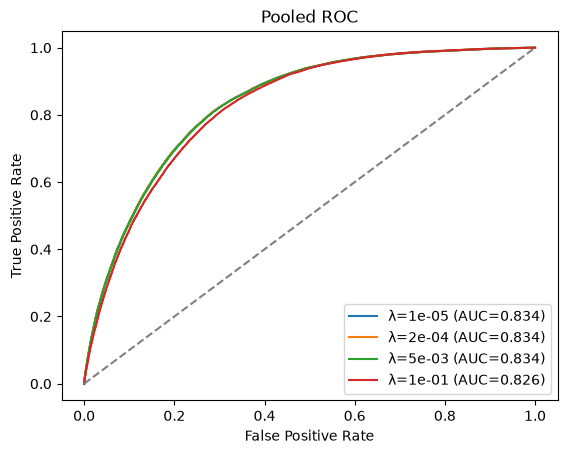

In [14]:
for r in results:
    false_pos_rate, true_pos_rate, auc = ds.ROC_AUC(y_train, r["val_scores"])
    plt.plot(false_pos_rate, true_pos_rate, label=f"λ={r['lam']:.0e} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend() 
plt.title("Pooled ROC")

lam=1.0e-05: F1=0.3849±0.0015  P=0.296  R=0.551  t*=0.182±0.004
lam=2.2e-04: F1=0.3849±0.0013  P=0.297  R=0.548  t*=0.184±0.005
lam=4.6e-03: F1=0.3824±0.0020  P=0.299  R=0.531  t*=0.206±0.005
lam=1.0e-01: F1=0.3712±0.0017  P=0.291  R=0.514  t*=0.360±0.000


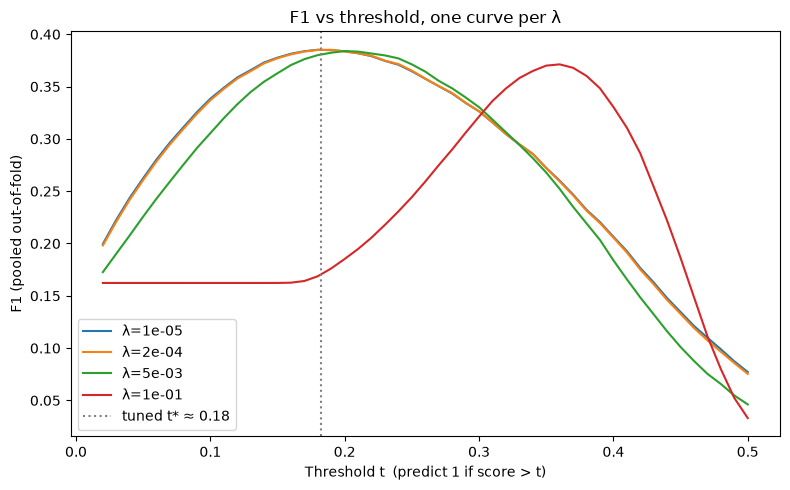

In [15]:
THS = np.linspace(0.02, 0.5, 49)          # thresholds 0.02 .. 0.50, step 0.01
all_idx = np.arange(len(y_train))

f1_table = []
for r in results:
    f1s, ts, precs, recs = [], [], [], []
    for st in r["fold_state"]:
        val_idx = st["val_idx"]
        tr_idx = np.setdiff1d(all_idx, val_idx)
        w, mu, sd = st["w"], st["mu"], st["sd"]

        p_tr = 0.5 * (1 + np.tanh(0.5 * (((x_tr_one_hot[tr_idx] - mu) / sd) @ w[1:] + w[0])))
        f1_tr = np.array([ds.F1_score(y_train[tr_idx], p_tr, t)[0] for t in THS])
        t_hat = THS[int(np.argmax(f1_tr))]

        p_val = r["val_scores"][val_idx]
        f1_val, (tp, fp, fn) = ds.F1_score(y_train[val_idx], p_val, t_hat)
        f1s.append(f1_val)
        precs.append(tp / (tp + fp) if (tp + fp) > 0 else 0.0)
        recs.append(tp / (tp + fn) if (tp + fn) > 0 else 0.0)
        ts.append(t_hat)

    f1_table.append({
        "gamma": r["gamma"], "lam": r["lam"],
        "f1": np.mean(f1s), "f1_std": np.std(f1s),
        "precision": np.mean(precs), "recall": np.mean(recs),
        "threshold": np.mean(ts), "threshold_std": np.std(ts),
    })
    e = f1_table[-1]
    print(f"lam={e['lam']:.1e}: F1={e['f1']:.4f}±{e['f1_std']:.4f}  "
        f"P={e['precision']:.3f}  R={e['recall']:.3f}  "
        f"t*={e['threshold']:.3f}±{e['threshold_std']:.3f}")

plt.figure(figsize=(8, 5))
for r in results:
    f1_curve = [ds.F1_score(y_train, r["val_scores"], t)[0] for t in THS]
    plt.plot(THS, f1_curve, label=f"λ={r['lam']:.0e}")
best_overall = max(f1_table, key=lambda e: e["f1"])
plt.axvline(best_overall["threshold"], color="grey", linestyle=":",
            label=f"tuned t* ≈ {best_overall['threshold']:.2f}")
plt.xlabel("Threshold t  (predict 1 if score > t)")
plt.ylabel("F1 (pooled out-of-fold)")
plt.title("F1 vs threshold, one curve per λ")
plt.legend()
plt.tight_layout()

Before we start doing any analysis on feature importance, we should first compute the correlation between features so that we can group highly correlated features together and compute their importance as a whole.

In [16]:
cor_mat = np.corrcoef(x_tr_one_hot, rowvar=False)
iu = np.triu_indices_from(cor_mat, k=1)

# Do some processing so that the dummy variables from the same categorical variable are not compared
stems = [str(h).rsplit('_', 1)[0] for h in header_one_hot]
is_dummy = [s in headers_cat_cleaned and str(h) != s
            for s, h in zip(stems, header_one_hot)]
same_parent = [is_dummy[i] and is_dummy[j] and stems[i] == stems[j]
               for i, j in zip(iu[0], iu[1])]
i_f, j_f = iu[0][~np.array(same_parent)], iu[1][~np.array(same_parent)]
pairs = np.argsort(-np.abs(cor_mat[i_f, j_f]))[:25]

print(f"{'feature A':<14}{'feature B':<14}{'corr':>8}")
for p in pairs:
    i, j = i_f[p], j_f[p]
    print(f"{header_one_hot[i]:<14}{header_one_hot[j]:<14}{cor_mat[i, j]:>+8.3f}")


feature A     feature B         corr
_LMTACT1_3.0  _LMTWRK1_3.0    +1.000
_LMTWRK1_3.0  _LMTSCL1_4.0    +1.000
_LMTACT1_3.0  _LMTSCL1_4.0    +1.000
_AGE80        FC60_           -0.969
_PACAT1       _PA150R2        +0.955
_MINAC21      PAMIN21_        +0.936
_LMTACT1_9.0  _LMTSCL1_9.0    +0.920
_MINAC11      PAMIN11_        +0.920
_PACAT1       _PA300R2        +0.887
_TOTINDA      _PA150R2        +0.884
_LMTWRK1_9.0  _LMTSCL1_9.0    +0.867
WTKG3         _BMI5           +0.866
_LMTACT1_9.0  _LMTWRK1_9.0    +0.853
_PA150R2      _PA300R2        +0.848
PAMIN11_      PAVIG11_        +0.807
_TOTINDA      _PACAT1         +0.801
_TOTINDA      _PA300R2        +0.798
_TOTINDA      ACTIN11_        -0.761
PAMIN21_      PAVIG21_        +0.757
ACTIN11_      _PA150R2        -0.749
ACTIN11_      _PA300R2        -0.743
_LMTWRK1_2.0  _LMTSCL1_3.0    +0.736
_LMTACT1_2.0  _LMTSCL1_3.0    +0.723
ACTIN11_      _PACAT1         -0.712
_LMTWRK1_2.0  _LMTSCL1_4.0    -0.706


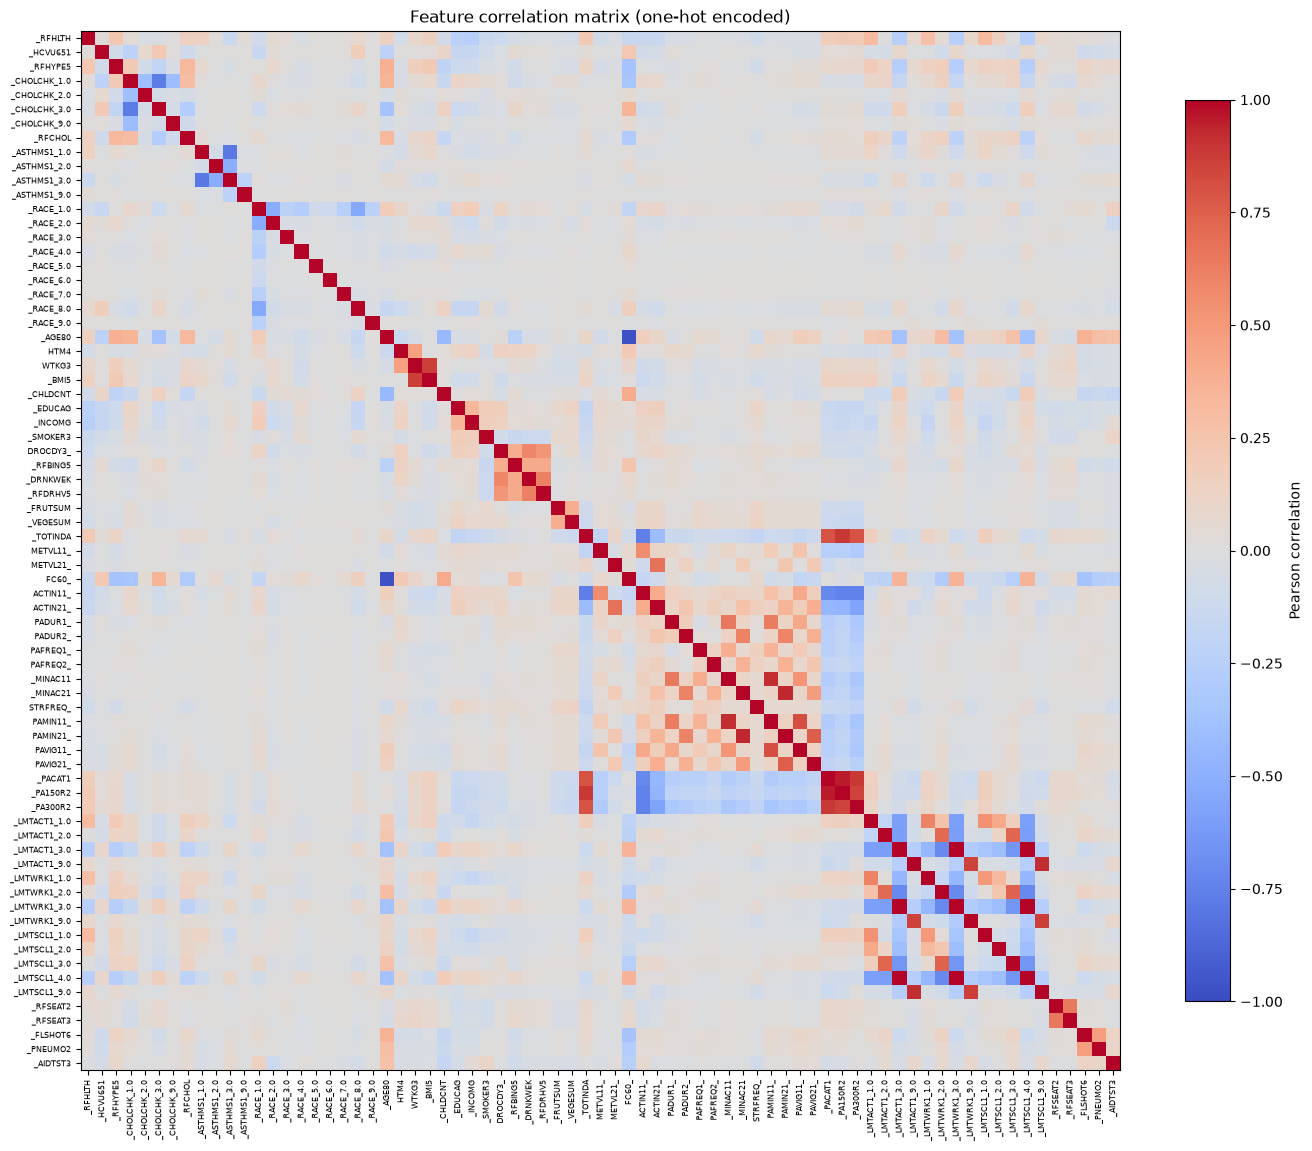

In [17]:
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(cor_mat, cmap="coolwarm", vmin=-1, vmax=1)

cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Pearson correlation")

ax.set_xticks(np.arange(len(header_one_hot)))
ax.set_yticks(np.arange(len(header_one_hot)))
ax.set_xticklabels(header_one_hot, rotation=90, fontsize=6)
ax.set_yticklabels(header_one_hot, fontsize=6)
ax.set_title("Feature correlation matrix (one-hot encoded)")

plt.tight_layout()
plt.show()

From this the model can be further simplified by removing some highly correlated variables. TBD... We can still start our feature importance analysis.

In [18]:
best = results[int(np.argmin([r["val_loss"] for r in results]))]               
N_REPEATS = 5
n_rows = len(y_train)
single_drops = {str(h): [] for h in header_one_hot}
base_aucs = []
for k, state in enumerate(best["fold_state"]):
    val = state["val_idx"]
    x_val = (x_tr_one_hot[val] - st["mu"]) / st["sd"]    
    y_val = y_train[val]
    w = state["w"]
    z_base = x_val @ w[1:] + w[0]
    contrib = x_val * w[1:]                               # per-column logit contributions
    base_auc = ds.ROC_AUC(y_val, 0.5 * (1 + np.tanh(0.5 * z_base)))[2]
    rng = np.random.default_rng(100 + k)
    base_aucs.append(base_auc)
    for j, h in enumerate(header_one_hot):
        drops = []
        for _ in range(N_REPEATS):
            perm = rng.permutation(len(y_val))
            contrib_diff = contrib[perm, j] - contrib[:, j]
            auc_perm = ds.ROC_AUC(y_val, 0.5 * (1 + np.tanh(0.5 * (z_base + contrib_diff))))[2]
            drops.append(base_auc - auc_perm)
        single_drops[str(h)].append(np.mean(drops))
    print(f"fold {k}: base AUC = {base_auc:.4f}")

# aggregate across folds and print0.881
imp_single = [(np.mean(d), np.std(d), h) for h, d in single_drops.items()]
print(f"\n{'column':<16}{'AUC drop':>10}{'std':>8}   (base AUC ~ {np.mean(base_aucs):.3f})")
for m, s, h in sorted(imp_single, reverse=True):
    print(f"{h:<16}{m:>+10.4f}{s:>8.4f}")

fold 0: base AUC = 0.8358
fold 1: base AUC = 0.8346
fold 2: base AUC = 0.8341
fold 3: base AUC = 0.8332
fold 4: base AUC = 0.8347

column            AUC drop     std   (base AUC ~ 0.834)
_RFHLTH            +0.0325  0.0008
FC60_              +0.0234  0.0008
_RFHYPE5           +0.0177  0.0009
_AGE80             +0.0171  0.0007
_RFCHOL            +0.0164  0.0006
HTM4               +0.0069  0.0004
_SMOKER3           +0.0041  0.0003
_INCOMG            +0.0016  0.0002
_PNEUMO2           +0.0008  0.0002
ACTIN11_           +0.0007  0.0002
WTKG3              +0.0007  0.0002
_EDUCAG            +0.0007  0.0002
_CHOLCHK_2.0       +0.0004  0.0001
_RACE_2.0          +0.0004  0.0001
DROCDY3_           +0.0004  0.0001
_TOTINDA           +0.0003  0.0001
_CHOLCHK_1.0       +0.0003  0.0000
_RFBING5           +0.0003  0.0001
_ASTHMS1_3.0       +0.0003  0.0002
_LMTSCL1_1.0       +0.0003  0.0001
_ASTHMS1_1.0       +0.0002  0.0001
METVL11_           +0.0002  0.0001
_RFSEAT2           +0.0002  0.0001
_RACE_7.

Based on these results the following variables can be removed due to low importance:

'_MINAC21', '_MINAC11', '_PA150R2', '_PA300R2', 'METVL11', 'METVL21', 'PADUR2_', 'PAFREQ2_', 'PAMIN21_', 'PAVIG21_', 'ACTIN21_', '_HCVU651', '_FLSHOT6' and '_AIDTST3'

The remaining ones are kept because some of them are categorical variables that are split into dummies, which means the importance of individual dummy columns may not be representative. And for the others, there roles could be uncertain and need further experiments.

In [19]:
further_drop = ['_MINAC21', '_MINAC11', '_PA150R2', '_PA300R2', 'METVL11_', 'METVL21_', 
                        'PADUR2_', 'PAFREQ2_', 'PAMIN21_', 'PAVIG21_', 'ACTIN21_', 
                        '_HCVU651', '_FLSHOT6', '_AIDTST3']

drop_idx = np.where(np.isin(cal_headers_cleaned, further_drop))[0]

x_train_cal_cleaned = np.delete(x_train_cal_cleaned, drop_idx, axis=1)
cal_headers_cleaned = np.delete(cal_headers_cleaned, drop_idx)

headers_num_cleaned = [h for h in headers_num_cleaned if h not in further_drop]
headers_num_cat_cleaned = [h for h in headers_num_cat_cleaned if h not in further_drop]
headers_cat_cleaned = [h for h in headers_cat_cleaned if h not in further_drop]

print("Remaining columns:", len(cal_headers_cleaned))   # expect 35

Remaining columns: 35


Now that the drops are done, we will go back to the list of raw variables (i.e. not calculated) to see whether we can add more useful ones to our model. In particular, the followings are worth investigating:

'CVDSTRK3', 'DIABETE3', 'DIFFWALK', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH' and 'SEX'

In [ ]:
raw_var_add_list = ['CVDSTRK3', 'DIABETE3', 'DIFFWALK', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'SEX']
raw_idx = [int(np.where(full_headers == h)[0][0]) for h in raw_var_add_list]   # assert len == len(raw_names)!
x_raw = x_train[:, raw_idx]
raw_headers = np.array(raw_var_add_list)

x_train_cal_cleaned = np.concatenate((x_train_cal_cleaned, x_raw), axis=1)
cal_headers_cleaned = np.concatenate((cal_headers_cleaned, raw_headers))

headers_num_cleaned += ["PHYSHLTH", "MENTHLTH"]                   
headers_num_cat_cleaned += ["GENHLTH"]
headers_cat_cleaned += ['DIABETE3']

for h in ["PHYSHLTH", "MENTHLTH"]:
    j = int(np.where(cal_headers_cleaned == h)[0][0])
    col = x_train_cal_cleaned[:, j]
    col[col == 88.0] = 0.0            # "none" -> true zero
    col[np.isin(col, [77.0, 99.0])] = np.nan
    col[np.isnan(col)] = np.median(col[~np.isnan(col)])

for h in ["GENHLTH", "DIFFWALK", "CVDSTRK3", "SEX"]:
    j = int(np.where(cal_headers_cleaned == h)[0][0])
    col = x_train_cal_cleaned[:, j]
    col[np.isin(col, [7.0, 9.0, 77.0, 99.0])] = np.nan
    v, c = np.unique(col[~np.isnan(col)], return_counts=True)
    col[np.isnan(col)] = v[np.argmax(c)]

j = int(np.where(cal_headers_cleaned == "DIABETE3")[0][0])
col = x_train_cal_cleaned[:, j]
col[np.isin(col, [7.0])] = 9.0                 
col[np.isnan(col)] = 9.0                 

for header in ['CVDSTRK3', 'DIFFWALK', 'SEX']:
    idx = int(np.where(cal_headers_cleaned == header)[0][0])
    col = x_train_cal_cleaned[:, idx]
    col[col == 1.0] = 0.0
    col[col == 2.0] = 1.0
    x_train_cal_cleaned[:, idx] = col



And we will run the same model again with this new data, and see whether the performance improves.

In [21]:
x_tr_one_hot, header_one_hot = helpers.one_hot(x_train_cal_cleaned, headers_cat_cleaned, cal_headers_cleaned)
print("Data dimensions after one-hot:", np.shape(x_tr_one_hot))

# Normalise a bit
y_train[y_train == -1] = 0

K = 5
folds_list = helpers.k_fold_split(len(y_train), K)
max_iters = 500
gamma_list = [0.1] # Set like this for now, add more candidates later
reg_list = np.logspace(-5, -1, 4)
results = []
for gamma in gamma_list:
    for lam in reg_list:
        tr_losses, val_losses, zero_one, aucs = [], [], [], []
        val_scores = np.zeros(len(y_train))
        fold_state = []
        for fold in tqdm(folds_list):
            x_tr_fold, y_tr_fold = x_tr_one_hot[fold[0]], y_train[fold[0]]
            # Centering and normalising
            std = x_tr_fold.std(axis = 0)
            mu = x_tr_fold.mean(axis = 0)
            std[std == 0] = 1
            x_tr_fold = np.c_[np.ones(len(x_tr_fold[:,0])), (x_tr_fold - mu) / std]
            x_val_fold, y_val_fold = x_tr_one_hot[fold[1]], y_train[fold[1]]
            x_val_fold = np.c_[np.ones(len(x_val_fold)), (x_val_fold - mu) / std]
            w_init = np.zeros(len(x_tr_fold[0,:]))
            w_fold, loss_fold = imp.reg_logistic_regression(y_tr_fold, x_tr_fold, lam, w_init, max_iters, gamma)
            
            tr_losses.append(loss_fold)
            val_losses.append(imp.logistic_loss(y_val_fold, x_val_fold, w_fold))
            val_score = 0.5 * (1 + np.tanh(0.5 * x_val_fold.dot(w_fold)))
            zero_one.append(np.mean((val_score > 0.5) != y_val_fold))
            fold_state.append({"w": w_fold, "mu": mu, "sd": std, "val_idx": fold[1]})
            
            false_pos_rate, true_pos_rate, auc_fold = ds.ROC_AUC(y_val_fold, val_score)
            aucs.append(auc_fold)
            val_scores[fold[1]] = val_score
            
        results.append({
            "gamma": gamma, "lam": lam,
            "train_loss": np.mean(tr_losses),
            "val_loss": np.mean(val_losses), "val_loss_std": np.std(val_losses),
            "01_loss": np.mean(zero_one),
            "gap": np.mean(val_losses) - np.mean(tr_losses),
            "val_scores": val_scores,
            "mean_auc": np.mean(aucs),
            "fold_state": fold_state
        })
        print("---Result---")
        print(f"learning rate = {gamma}, regulariser = {lam:.1e}:")
        print(f"validation logistic loss = {results[-1]['val_loss']:.4f}±{results[-1]['val_loss_std']:.4f}, 0-1 loss (proportion of mistake) = {results[-1]['01_loss']:.4f}, train & validation loss gap = {results[-1]['gap']:.4f}")
        print(f"mean AUC across fold = {results[-1]['mean_auc']:.4f}")
        print("------------")

Data dimensions after one-hot: (328135, 70)


100%|██████████| 5/5 [01:03<00:00, 12.70s/it]


---Result---
learning rate = 0.1, regulariser = 1.0e-05:
validation logistic loss = 0.2284±0.0016, 0-1 loss (proportion of mistake) = 0.0863, train & validation loss gap = 0.0002
mean AUC across fold = 0.8529
------------


100%|██████████| 5/5 [01:07<00:00, 13.49s/it]


---Result---
learning rate = 0.1, regulariser = 2.2e-04:
validation logistic loss = 0.2286±0.0016, 0-1 loss (proportion of mistake) = 0.0863, train & validation loss gap = 0.0002
mean AUC across fold = 0.8529
------------


100%|██████████| 5/5 [00:57<00:00, 11.47s/it]


---Result---
learning rate = 0.1, regulariser = 4.6e-03:
validation logistic loss = 0.2359±0.0016, 0-1 loss (proportion of mistake) = 0.0862, train & validation loss gap = 0.0002
mean AUC across fold = 0.8525
------------


100%|██████████| 5/5 [01:07<00:00, 13.44s/it]

---Result---
learning rate = 0.1, regulariser = 1.0e-01:
validation logistic loss = 0.3800±0.0010, 0-1 loss (proportion of mistake) = 0.0877, train & validation loss gap = 0.0001
mean AUC across fold = 0.8442
------------


Text(0.5, 1.0, 'Pooled ROC')

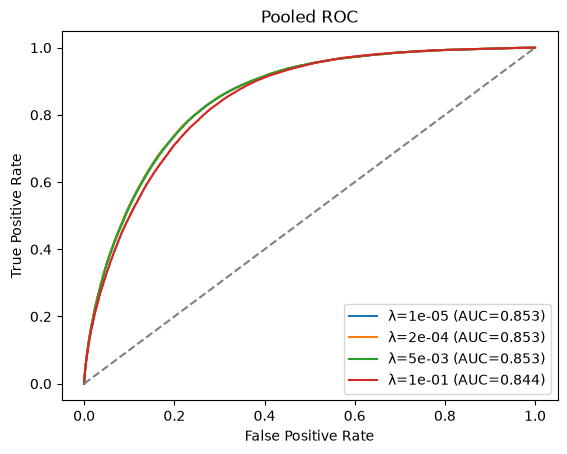

In [22]:
for r in results:
    false_pos_rate, true_pos_rate, auc = ds.ROC_AUC(y_train, r["val_scores"])
    plt.plot(false_pos_rate, true_pos_rate, label=f"λ={r['lam']:.0e} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend() 
plt.title("Pooled ROC")

lam=1.0e-05: F1=0.4128±0.0020  P=0.332  R=0.547  t*=0.196±0.005
lam=2.2e-04: F1=0.4124±0.0018  P=0.331  R=0.548  t*=0.196±0.005
lam=4.6e-03: F1=0.4109±0.0018  P=0.329  R=0.547  t*=0.214±0.005
lam=1.0e-01: F1=0.3932±0.0015  P=0.308  R=0.542  t*=0.370±0.000


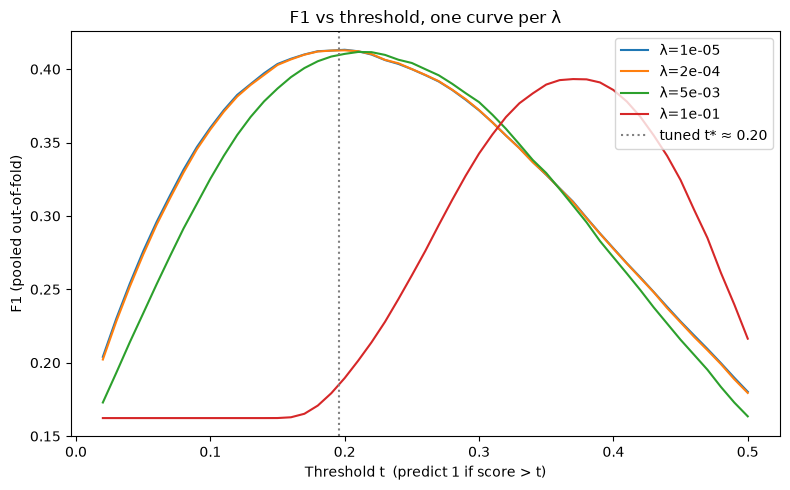

In [23]:
THS = np.linspace(0.02, 0.5, 49)          # thresholds 0.02 .. 0.50, step 0.01
all_idx = np.arange(len(y_train))

f1_table = []
for r in results:
    f1s, ts, precs, recs = [], [], [], []
    for st in r["fold_state"]:
        val_idx = st["val_idx"]
        tr_idx = np.setdiff1d(all_idx, val_idx)
        w, mu, sd = st["w"], st["mu"], st["sd"]

        p_tr = 0.5 * (1 + np.tanh(0.5 * (((x_tr_one_hot[tr_idx] - mu) / sd) @ w[1:] + w[0])))
        f1_tr = np.array([ds.F1_score(y_train[tr_idx], p_tr, t)[0] for t in THS])
        t_hat = THS[int(np.argmax(f1_tr))]

        p_val = r["val_scores"][val_idx]
        f1_val, (tp, fp, fn) = ds.F1_score(y_train[val_idx], p_val, t_hat)
        f1s.append(f1_val)
        precs.append(tp / (tp + fp) if (tp + fp) > 0 else 0.0)
        recs.append(tp / (tp + fn) if (tp + fn) > 0 else 0.0)
        ts.append(t_hat)

    f1_table.append({
        "gamma": r["gamma"], "lam": r["lam"],
        "f1": np.mean(f1s), "f1_std": np.std(f1s),
        "precision": np.mean(precs), "recall": np.mean(recs),
        "threshold": np.mean(ts), "threshold_std": np.std(ts),
    })
    e = f1_table[-1]
    print(f"lam={e['lam']:.1e}: F1={e['f1']:.4f}±{e['f1_std']:.4f}  "
        f"P={e['precision']:.3f}  R={e['recall']:.3f}  "
        f"t*={e['threshold']:.3f}±{e['threshold_std']:.3f}")

plt.figure(figsize=(8, 5))
for r in results:
    f1_curve = [ds.F1_score(y_train, r["val_scores"], t)[0] for t in THS]
    plt.plot(THS, f1_curve, label=f"λ={r['lam']:.0e}")
best_overall = max(f1_table, key=lambda e: e["f1"])
plt.axvline(best_overall["threshold"], color="grey", linestyle=":",
            label=f"tuned t* ≈ {best_overall['threshold']:.2f}")
plt.xlabel("Threshold t  (predict 1 if score > t)")
plt.ylabel("F1 (pooled out-of-fold)")
plt.title("F1 vs threshold, one curve per λ")
plt.legend()
plt.tight_layout()